# Should we keep paying for this ad campaign?

## 0. The decision this analysis changes

> **The marketing team has to decide whether to renew the campaign budget next quarter and whether to change how it is spent.**

Every analysis below answers one of three business questions:

| # | Business question | Decision it informs |
|---|---|---|
| **BQ1** | Does the ad *cause* more purchases and how many? | Is the campaign doing anything at all? |
| **BQ2** | Is it worth the money? | Renew or cut the budget |
| **BQ3** | Where does it work: at what ad frequency and on which days? | How to spend the budget |

**Answer up front:** yes, the ad causes about 43% more purchases. It pays for itself if each sale earns more than roughly
$16 in profit (at a typical $5 CPM). But the lift only shows up for users who see the ad many times.
→ **Keep funding the campaign and run a frequency test before the next budget cycle.**

| Chapter | |
|---|---|
| 1 | The dataset |
| 2 | Data quality & Sample Ratio Mismatch |
| 3 | Exploratory analysis |
| 4 | BQ1: Did the ad cause more purchases? |
| 5 | How sure are we? Bootstrap, Bayesian, power |
| 6 | BQ2: Is it worth the money? |
| 7 | BQ3: Where does it work? |
| 8 | Recommendation & takeaway |

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multitest import multipletests
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ab_stats import srm_check, ztest_props, bootstrap_lift, bayes_ab, power_mde, required_sample_size

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SITE_DATA = ROOT / "docs" / "data"; SITE_DATA.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.05)
PALETTE = {"psa": "#9aa5b1", "ad": "#2f6fdb"}
LABELS = {"psa": "Control (PSA)", "ad": "Test (Ad)"}
ALPHA = 0.05

def plain_p(p):
    """Translate a p-value into a sentence a stakeholder can read."""
    if p < 1e-12: return "less than 1 in a trillion"
    if p < 1e-6:  return "less than 1 in a million"
    return f"about 1 in {1 / p:,.0f}"

## 1. The dataset

**Source:** [Marketing A/B Testing](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing) on Kaggle, 588,101 users, one row per user.

**The set-up:** most users were shown a product **advertisement** (test group). A small hold-out group saw a
**public-service announcement (PSA)** in the same ad slot (control group). Because the PSA fills the same space,
any difference in purchases can be credited to the ad's *content*, not to simply having an ad there.

| Column | Meaning | How it's used |
|---|---|---|
| `user id` | unique user | duplicate check |
| `test group` | `ad` (test) or `psa` (control) | the experiment split |
| `converted` | did the user buy? | **primary metric** |
| `total ads` | number of ads the user saw | frequency analysis, impressions for the cost model |
| `most ads day` | weekday on which the user saw the most ads | timing analysis |
| `most ads hour` | hour on which the user saw the most ads | not used (see below) |

**What to keep in mind about this data:**
- The origin isn't documented (company, product, dates). It may be synthetic, so the findings show the *method*,
  not facts about a real company.
- There is **no revenue or cost data**. Chapter 6 works around this with a break-even analysis.
- `total ads` and `most ads day` are recorded *after* users were assigned to a group, so analyses that split by them
  are descriptive, not causal.
- `most ads hour` is left out on purpose. It doesn't connect to any decision we can make here and a chart that answers
  nothing only distracts from the ones that do.

In [2]:
df = pd.read_csv(ROOT / "data" / "marketing_AB.csv", index_col=0)
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
df.head()

,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


## 2. Data quality checks

In [3]:
checks = {
    "rows": len(df),
    "missing values": int(df.isna().sum().sum()),
    "duplicate user ids": int(df["user_id"].duplicated().sum()),
    "users in both groups": int(df.groupby("user_id")["test_group"].nunique().gt(1).sum()),
    "groups": sorted(df["test_group"].unique()),
}
checks

{'rows': 588101,
 'missing values': 0,
 'duplicate user ids': 0,
 'users in both groups': 0,
 'groups': ['ad', 'psa']}

### Sample Ratio Mismatch (SRM)

The groups are deliberately unequal: about **96% ad / 4% PSA**. The company wants to reach as many people as possible,
so it only keeps a small hold-out. An SRM check confirms that the observed split matches the *intended* one. If it doesn't,
the assignment is broken (bots, logging bugs) and no result can be trusted.

In [4]:
n = df["test_group"].value_counts()
srm = srm_check(n_control=n["psa"], n_test=n["ad"], expected_control_share=0.04)
print(f"observed control share: {n['psa'] / n.sum():.4%}")
print(f"chi2 = {srm.chi2:.2f}, p = {srm.p_value:.3g} → SRM detected: {srm.mismatch}")

observed control share: 4.0000%
chi2 = 0.00, p = 1 → SRM detected: False


The control share is **exactly 4.00%**, which suggests the dataset was sampled to a fixed ratio by design.
**Honest caveat:** because the expected share was inferred from the data, this check can't fail here. In a real
experiment, take the expected ratio from the experiment configuration *before* looking at the data. Then the
same function becomes a real safeguard (see `tests/test_ab_stats.py`, where it catches a 55/45 split meant to be 50/50).

## 3. Exploratory analysis

In [5]:
summary = (df.groupby("test_group")["converted"]
             .agg(users="count", conversions="sum", rate="mean")
             .loc[["psa", "ad"]])
summary["rate_%"] = (summary["rate"] * 100).round(3)
summary

,users,conversions,rate,rate_%
test_group,,,,
psa,23524,420,0.017854,1.785
ad,564577,14423,0.025547,2.555


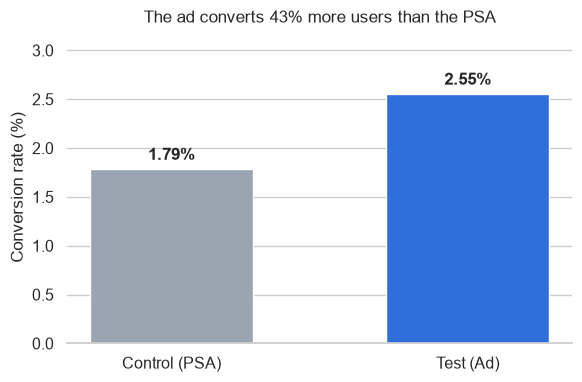

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([LABELS["psa"], LABELS["ad"]], summary["rate"] * 100,
              color=[PALETTE["psa"], PALETTE["ad"]], width=0.55)
ax.bar_label(bars, fmt="%.2f%%", padding=4, fontweight="bold")
ax.set_ylabel("Conversion rate (%)"); ax.set_ylim(0, 3.2); ax.grid(axis="x", visible=False)
ax.set_title("The ad converts 43% more users than the PSA")
sns.despine(left=True); plt.tight_layout(); plt.savefig(FIG / "conversion_by_group.png", dpi=200)
plt.show()

## 4. BQ1: Did the ad cause more purchases?

In [7]:
c, t = summary.loc["psa"], summary.loc["ad"]
z = ztest_props(int(c.conversions), int(c.users), int(t.conversions), int(t.users))
chi2, p_chi, *_ = stats.chi2_contingency(pd.crosstab(df["test_group"], df["converted"]), correction=False)
incremental_total = z.abs_diff * t.users

print(f"Control rate     : {z.rate_control:.4%}")
print(f"Test rate        : {z.rate_test:.4%}")
print(f"Absolute uplift  : {z.abs_diff * 100:+.3f} pp  (95% CI {z.ci_low * 100:.3f} to {z.ci_high * 100:.3f} pp)")
print(f"Relative lift    : {z.rel_lift:+.1%}")
print(f"z = {z.z:.2f}, p = {z.p_value:.2e}   (chi-square check: chi2 = {chi2:.2f} = z²)")
print()
print(f"In plain words: if the ad had no effect, a gap this large would happen by chance {plain_p(z.p_value)} times.")
print(f"Purchases caused by the campaign: ~{incremental_total:,.0f} "
      f"(95% CI {z.ci_low * t.users:,.0f} to {z.ci_high * t.users:,.0f})")

Control rate     : 1.7854%
Test rate        : 2.5547%
Absolute uplift  : +0.769 pp  (95% CI 0.595 to 0.943 pp)
Relative lift    : +43.1%
z = 7.37, p = 1.71e-13   (chi-square check: chi2 = 54.32 = z²)

In plain words: if the ad had no effect, a gap this large would happen by chance less than 1 in a trillion times.
Purchases caused by the campaign: ~4,343 (95% CI 3,360 to 5,326)


**Answer to BQ1: yes.** The ad raises conversion from 1.79% to 2.55%. That is about 4,300 purchases that would not have happened
without it. The 95% confidence interval doesn't come close to zero.

## 5. How sure are we?

A stakeholder will only act on a number they trust. Three independent checks:

### 5a. Bootstrap (no normal-approximation assumption)

With only 420 conversions in the control group, it's worth checking the z-test against a method that makes fewer assumptions.

Bootstrap relative lift: +43.1%  (95% CI +30.6% to +57.9%)


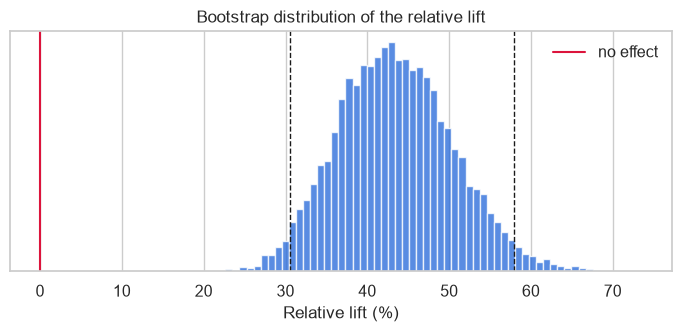

In [8]:
y_c = df.loc[df.test_group == "psa", "converted"].to_numpy()
y_t = df.loc[df.test_group == "ad", "converted"].to_numpy()
boot = bootstrap_lift(y_c, y_t, n_boot=10_000)
print(f"Bootstrap relative lift: {boot['lift']:+.1%}  (95% CI {boot['ci_low']:+.1%} to {boot['ci_high']:+.1%})")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(boot["samples"] * 100, bins=60, color=PALETTE["ad"], alpha=0.8)
for v in (boot["ci_low"], boot["ci_high"]): ax.axvline(v * 100, ls="--", c="k", lw=1)
ax.axvline(0, c="crimson", lw=1.5, label="no effect")
ax.set(title="Bootstrap distribution of the relative lift", xlabel="Relative lift (%)", yticks=[])
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(FIG / "bootstrap_lift.png", dpi=200); plt.show()

### 5b. Bayesian view: "how likely is it that the ad is better?"

This is the question stakeholders actually ask. We use a Beta-Binomial model with a flat prior.

P(ad beats PSA)  : >99.99%
Expected lift    : +43.1%  (95% credible interval +29.9% to +57.5%)


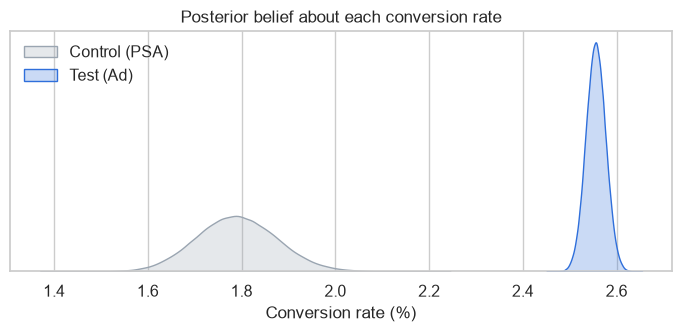

In [9]:
bayes = bayes_ab(int(c.conversions), int(c.users), int(t.conversions), int(t.users))
prob_txt = ">99.99%" if bayes["prob_test_better"] > 0.9999 else f"{bayes['prob_test_better']:.2%}"
print(f"P(ad beats PSA)  : {prob_txt}")
print(f"Expected lift    : {bayes['expected_lift']:+.1%}  (95% credible interval "
      f"{bayes['lift_ci'][0]:+.1%} to {bayes['lift_ci'][1]:+.1%})")

fig, ax = plt.subplots(figsize=(7, 3.5))
for key, name in [("post_control", "psa"), ("post_test", "ad")]:
    sns.kdeplot(bayes[key] * 100, ax=ax, fill=True, color=PALETTE[name], label=LABELS[name])
ax.set(title="Posterior belief about each conversion rate", xlabel="Conversion rate (%)", yticks=[], ylabel="")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(FIG / "bayesian_posteriors.png", dpi=200); plt.show()

### 5c. Was the test big enough?

In [10]:
mde = power_mde(z.rate_control, int(c.users), int(t.users))
n_bal = required_sample_size(z.rate_control, mde)
print(f"Smallest uplift this design could reliably detect (80% power): {mde * 100:.3f} pp ({mde / z.rate_control:.0%} relative)")
print(f"Observed uplift: {z.abs_diff * 100:.3f} pp, about {z.abs_diff / mde:.1f}× the detection threshold.")
print(f"A 50/50 split would need only {sum(n_bal):,} users in total for the same sensitivity.")

Smallest uplift this design could reliably detect (80% power): 0.247 pp (14% relative)
Observed uplift: 0.769 pp, about 3.1× the detection threshold.
A 50/50 split would need only 90,334 users in total for the same sensitivity.


**Judgement call on the 96/4 split.** A 50/50 split is statistically more efficient, but it would have withheld the ad from
half the audience. The 4% hold-out is a reasonable trade-off: the company keeps almost all the ad's revenue *and* gets a
valid measurement. Section 6 puts a price on that hold-out.

## 6. BQ2: Is it worth the money?

The dataset has no cost or revenue figures, so instead of guessing them, we ask: **at what price does the campaign pay off?**

`total_ads` gives us the number of ad impressions served. Combined with the incremental purchases from chapter 4, we
get the **number of extra purchases per 1,000 impressions**. Ads are usually bought per 1,000 impressions (CPM),
so this turns directly into a cost per extra purchase.

In [11]:
impressions = int(df.loc[df.test_group == "ad", "total_ads"].sum())
inc_per_1000 = incremental_total / impressions * 1000

breakeven = pd.DataFrame({"CPM ($ per 1,000 impressions)": [1, 2, 5, 10]})
breakeven["campaign cost ($)"] = breakeven.iloc[:, 0] * impressions / 1000
breakeven["cost per extra purchase ($)"] = breakeven.iloc[:, 0] / inc_per_1000
holdout_cost = z.abs_diff * c.users

print(f"Ad impressions served          : {impressions:,}")
print(f"Extra purchases                : {incremental_total:,.0f}")
print(f"Extra purchases per 1,000 imps : {inc_per_1000:.3f}")
print(f"Purchases 'lost' to the 4% hold-out: ~{holdout_cost:,.0f}, the price of being able to measure any of this")
breakeven.round(0).astype(int)

Ad impressions served          : 14,014,701
Extra purchases                : 4,343
Extra purchases per 1,000 imps : 0.310
Purchases 'lost' to the 4% hold-out: ~181, the price of being able to measure any of this


,"CPM ($ per 1,000 impressions)",campaign cost ($),cost per extra purchase ($)
0,1,14015,3
1,2,28029,6
2,5,70074,16
3,10,140147,32


**Answer to BQ2: it depends on one number the business knows and we don't, the profit per sale.**
At a typical $5 CPM, each extra purchase costs about **$16** in ads. If a sale earns more profit than that, the campaign pays
for itself. That turns an open-ended question into one quick check with the finance team.

The hold-out cost about 181 purchases, under 5% of what the campaign generated. That's a cheap price for knowing the campaign works at all.

## 7. BQ3: Where does it work?

### 7a. Ad frequency, the biggest lever

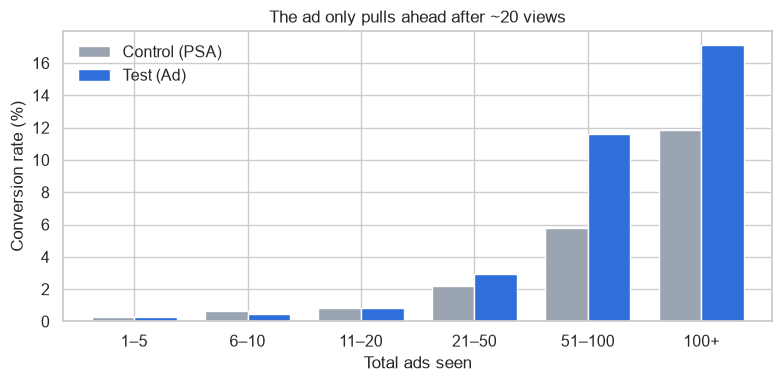

,psa,ad,users
ads_bucket,,,
1–5,0.28,0.25,177823
6–10,0.67,0.49,82952
11–20,0.82,0.84,127484
21–50,2.18,2.92,130776
51–100,5.77,11.63,46002
100+,11.88,17.14,23064


In [12]:
bins = [0, 5, 10, 20, 50, 100, np.inf]
labels = ["1–5", "6–10", "11–20", "21–50", "51–100", "100+"]
df["ads_bucket"] = pd.cut(df["total_ads"], bins=bins, labels=labels)
by_exposure = df.groupby(["ads_bucket", "test_group"], observed=True)["converted"].mean().unstack()[["psa", "ad"]]
exposure_n = df.groupby("ads_bucket", observed=True).size()

fig, ax = plt.subplots(figsize=(8, 4))
(by_exposure * 100).plot(kind="bar", ax=ax, color=PALETTE.values(), width=0.75)
ax.set(title="The ad only pulls ahead after ~20 views", xlabel="Total ads seen", ylabel="Conversion rate (%)")
ax.tick_params(axis="x", rotation=0); ax.legend([LABELS["psa"], LABELS["ad"]], frameon=False)
plt.tight_layout(); plt.savefig(FIG / "conversion_by_exposure.png", dpi=200); plt.show()
pd.concat([(by_exposure * 100).round(2), exposure_n.rename("users")], axis=1)

In [13]:
FREQ_CUT = 20
low = df.total_ads <= FREQ_CUT
ad_mask = df.test_group == "ad"

def group_test(mask):
    s = df[mask].groupby("test_group")["converted"].agg(["sum", "count"])
    return ztest_props(int(s.loc["psa", "sum"]), int(s.loc["psa", "count"]), int(s.loc["ad", "sum"]), int(s.loc["ad", "count"]))

low_t, high_t = group_test(low), group_test(~low)
low_user_share = low.mean()
low_imp_share = df.loc[ad_mask & low, "total_ads"].sum() / impressions

print(f"Users who saw ≤{FREQ_CUT} ads : {low_user_share:.0%} of users, {low_imp_share:.0%} of ad impressions")
print(f"  lift: {low_t.rel_lift:+.1%}  (95% CI {low_t.ci_low * 100:+.3f} to {low_t.ci_high * 100:+.3f} pp, p = {low_t.p_value:.2f})")
print(f"Users who saw >{FREQ_CUT} ads : lift {high_t.rel_lift:+.1%}  (p = {high_t.p_value:.1e})")

Users who saw ≤20 ads : 66% of users, 21% of ad impressions
  lift: -3.2%  (95% CI -0.131 to +0.099 pp, p = 0.78)
Users who saw >20 ads : lift +55.7%  (p = 4.0e-17)


**Finding: about a fifth of the ad budget shows no measurable effect.** Two in three users saw 20 or fewer ads. For them the ad
shows no lift (the point estimate is even slightly negative) and they account for about 21% of all impressions.
Above 20 views, the ad clearly pulls ahead.

**Why this is a hypothesis, not a conclusion:** `total_ads` isn't randomised. Heavy platform users see more ads *and* may
simply be keener buyers. So we can't say "cap at 20 ads and save 21%". What we *can* say is that it is the
highest-value thing to test next, because it is the biggest potential saving.

### 7b. Weekday: should budget move between days?

Here the analysis needs restraint. Testing 7 days means 7 chances of a false positive (about 30% at α = 0.05),
so we apply the Holm correction.

In [14]:
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
rows = []
for day in DAYS:
    r = group_test(df.most_ads_day == day)
    rows.append({"day": day, "psa_users": int(((df.most_ads_day == day) & ~ad_mask).sum()),
                 "rate_psa_%": r.rate_control * 100, "rate_ad_%": r.rate_test * 100,
                 "lift_%": r.rel_lift * 100, "p_raw": r.p_value})
seg = pd.DataFrame(rows)
seg["p_holm"] = multipletests(seg.p_raw, method="holm")[1]
seg["significant_holm"] = seg.p_holm < ALPHA
seg.round(4)

,day,psa_users,rate_psa_%,rate_ad_%,lift_%,p_raw,p_holm,significant_holm
0,Monday,3502,2.2559,3.3241,47.3553,0.0005,0.0025,True
1,Tuesday,2907,1.4448,3.0440,110.6909,0.0000,0.0000,True
2,Wednesday,3490,1.5759,2.5356,60.8945,0.0004,0.0023,True
3,Thursday,3905,2.0230,2.1637,6.9532,0.5548,0.5548,False
4,Friday,3803,1.6303,2.2465,37.7971,0.0116,0.0347,True
5,Saturday,2858,1.3996,2.1307,52.2354,0.0075,0.0299,True
6,Sunday,3059,2.0595,2.4620,19.5430,0.1572,0.3144,False


**Answer: don't move budget between weekdays yet.** Five days show a significant lift after correction. Thursday and Sunday don't,
but with only about 3,000 control users per day that means "not enough evidence", not "no effect". More importantly,
`most_ads_day` is the day users *saw* the most ads, not the day they *bought*. That makes it too weak a basis for
moving money. Being able to say "this analysis does **not** support a change" is just as useful as finding one.

## 8. Recommendation & takeaway

In [15]:
print(f"BQ1  The ad causes ~{incremental_total:,.0f} extra purchases (+{z.rel_lift:.0%}), "
      f"chance explanation {plain_p(z.p_value)}.")
print(f"BQ2  At a $5 CPM each extra purchase costs ~${5 / inc_per_1000:.0f}. Worth it if profit per sale is higher.")
print(f"BQ3  {low_imp_share:.0%} of impressions go to low-frequency users with no measurable lift. Weekday data doesn't support moving budget.")

BQ1  The ad causes ~4,343 extra purchases (+43%), chance explanation less than 1 in a trillion.
BQ2  At a $5 CPM each extra purchase costs ~$16. Worth it if profit per sale is higher.
BQ3  21% of impressions go to low-frequency users with no measurable lift. Weekday data doesn't support moving budget.


### ✅ Recommendation: keep funding the campaign and test frequency before the next budget cycle

1. **Renew the budget.** The ad works: about 4,300 extra purchases, +43% and three methods agree.
2. **Confirm profitability with finance.** The campaign pays off if profit per sale is above about $16 (at a $5 CPM).
3. **Run a frequency experiment.** Randomise users into frequency caps (e.g. 10 / 20 / 40 ads). About 21% of impressions
   show no measurable lift today and that's the biggest potential saving.
4. **Keep a small hold-out in every future campaign.** It cost about 181 purchases and is the only reason we can measure anything.
5. **Don't reallocate by weekday.** The data doesn't support it.

> **Takeaway in one sentence:** *The ad works and likely pays for itself, but about a fifth of the spend may be wasted
> on users who don't see it often enough, so the next step is to test frequency, not to spend more.*

### Limitations
- The dataset's origin is undocumented and it may be synthetic.
- There's no cost or revenue data, so profitability is a break-even range, not a fixed figure.
- Each converted user is counted as one purchase, because purchase value is unknown.
- Frequency and weekday findings are descriptive (measured after assignment).
- The intended split ratio is inferred, not documented.

In [16]:
# Export the key numbers and chart data for the portfolio website (docs/index.html)
results = {
    "n_users": int(n.sum()), "n_control": int(c.users), "n_test": int(t.users),
    "conv_control": int(c.conversions), "conv_test": int(t.conversions),
    "rate_control": z.rate_control, "rate_test": z.rate_test,
    "abs_diff": z.abs_diff, "ci_low": z.ci_low, "ci_high": z.ci_high,
    "rel_lift": z.rel_lift, "z": z.z, "p_value": z.p_value, "p_plain": plain_p(z.p_value),
    "srm_p": srm.p_value, "control_share": float(n["psa"] / n.sum()),
    "boot_ci": [boot["ci_low"], boot["ci_high"]],
    "bayes_prob": bayes["prob_test_better"], "bayes_lift_ci": list(bayes["lift_ci"]),
    "mde_abs": mde, "n_balanced_total": int(sum(n_bal)),
    "incremental_total": float(incremental_total),
    "incremental_ci": [float(z.ci_low * t.users), float(z.ci_high * t.users)],
    "impressions": impressions, "inc_per_1000": float(inc_per_1000), "holdout_cost": float(holdout_cost),
    "breakeven": [{"cpm": int(r.iloc[0]), "cost": float(r.iloc[1]), "per_purchase": float(r.iloc[2])} for _, r in breakeven.iterrows()],
    "freq_cut": FREQ_CUT, "low_user_share": float(low_user_share), "low_imp_share": float(low_imp_share),
    "low_lift": low_t.rel_lift, "low_p": low_t.p_value, "high_lift": high_t.rel_lift, "high_p": high_t.p_value,
    "boot_hist": np.histogram(boot["samples"] * 100, bins=50)[0].tolist(),
    "boot_edges": np.histogram(boot["samples"] * 100, bins=50)[1].round(3).tolist(),
    "by_exposure": {"buckets": labels, "psa": (by_exposure.psa * 100).round(3).tolist(), "ad": (by_exposure.ad * 100).round(3).tolist()},
    "segments": seg[["day", "lift_%", "p_raw", "p_holm", "significant_holm"]].round(6).to_dict("records"),
}
(SITE_DATA / "results.json").write_text(json.dumps(results, indent=1, default=float))
print("saved", SITE_DATA / "results.json")

saved /Users/k.bozan.2/Documents/Job Applications/ab-testing-marketing-campaign/docs/data/results.json
